# Project 3: Analyzing Flight Interconnected Data

## Installing Required Packages

In [1]:
!pip install graphframes

## Creating session

In [2]:
import pyspark
from delta import configure_spark_with_delta_pip
from graphframes import GraphFrame

from pyspark.sql.functions import month, col, count, lit, round
from pyspark.sql.functions import sum as spark_sum

# For visuals
import matplotlib.pyplot as plt
import seaborn as sns
from pyspark.sql.functions import col
import networkx as nx

# Prepare the Spark builder
builder = pyspark.sql.SparkSession.builder.appName("Graphs_Practice") \
    .config("spark.sql.extensions", "io.delta.sql.DeltaSparkSessionExtension") \
    .config("spark.sql.catalog.spark_catalog", "org.apache.spark.sql.delta.catalog.DeltaCatalog")

spark = configure_spark_with_delta_pip(builder,extra_packages=["graphframes:graphframes:0.8.4-spark3.5-s_2.12"]).getOrCreate()
spark.conf.set("spark.sql.shuffle.partitions", spark._sc.defaultParallelism)

spark.conf.set("spark.sql.repl.eagerEval.enabled",True) # OK for exploration, not great for performance
spark.conf.set("spark.sql.repl.eagerEval.truncate", 500)

## Loading Dataset

The kaggle link given in the assignment contains datasets from 2009 to 2018  
For this project we are going to use dataset from 2016

In [3]:
flight_df = spark.read.csv("2016.csv", header=True, inferSchema=True)

### Preview

In [4]:
display(flight_df.limit(10)) ## displaying first 10 rows

FL_DATE,OP_CARRIER,OP_CARRIER_FL_NUM,ORIGIN,DEST,CRS_DEP_TIME,DEP_TIME,DEP_DELAY,TAXI_OUT,WHEELS_OFF,WHEELS_ON,TAXI_IN,CRS_ARR_TIME,ARR_TIME,ARR_DELAY,CANCELLED,CANCELLATION_CODE,DIVERTED,CRS_ELAPSED_TIME,ACTUAL_ELAPSED_TIME,AIR_TIME,DISTANCE,CARRIER_DELAY,WEATHER_DELAY,NAS_DELAY,SECURITY_DELAY,LATE_AIRCRAFT_DELAY,Unnamed: 27
2016-01-01,DL,1248,DTW,LAX,1935,1935.0,0.0,23.0,1958.0,2107.0,13.0,2144,2120.0,-24.0,0.0,NULL,0.0,309.0,285.0,249.0,1979.0,NULL,NULL,NULL,NULL,NULL,NULL
2016-01-01,DL,1251,ATL,GRR,2125,2130.0,5.0,13.0,2143.0,2315.0,4.0,2321,2319.0,-2.0,0.0,NULL,0.0,116.0,109.0,92.0,640.0,NULL,NULL,NULL,NULL,NULL,NULL
2016-01-01,DL,1254,LAX,ATL,2255,2256.0,1.0,19.0,2315.0,542.0,5.0,600,547.0,-13.0,0.0,NULL,0.0,245.0,231.0,207.0,1947.0,NULL,NULL,NULL,NULL,NULL,NULL
2016-01-01,DL,1255,SLC,ATL,1656,1700.0,4.0,12.0,1712.0,2205.0,8.0,2229,2213.0,-16.0,0.0,NULL,0.0,213.0,193.0,173.0,1590.0,NULL,NULL,NULL,NULL,NULL,NULL
2016-01-01,DL,1256,BZN,MSP,900,1012.0,72.0,63.0,1115.0,1416.0,4.0,1216,1420.0,124.0,0.0,NULL,0.0,136.0,188.0,121.0,874.0,72.0,0.0,52.0,0.0,0.0,NULL
2016-01-01,DL,1257,ATL,BNA,1233,1356.0,83.0,22.0,1418.0,1356.0,6.0,1239,1402.0,83.0,0.0,NULL,0.0,66.0,66.0,38.0,214.0,43.0,0.0,0.0,0.0,40.0,NULL
2016-01-01,DL,1257,BNA,ATL,1320,1446.0,86.0,15.0,1501.0,1638.0,6.0,1530,1644.0,74.0,0.0,NULL,0.0,70.0,58.0,37.0,214.0,3.0,0.0,0.0,0.0,71.0,NULL
2016-01-01,DL,1258,ATL,JAX,945,946.0,1.0,19.0,1005.0,1050.0,3.0,1050,1053.0,3.0,0.0,NULL,0.0,65.0,67.0,45.0,270.0,NULL,NULL,NULL,NULL,NULL,NULL
2016-01-01,DL,1258,JAX,ATL,1145,1144.0,-1.0,12.0,1156.0,1239.0,8.0,1302,1247.0,-15.0,0.0,NULL,0.0,77.0,63.0,43.0,270.0,NULL,NULL,NULL,NULL,NULL,NULL
2016-01-01,DL,1259,ATL,OKC,2110,2107.0,-3.0,16.0,2123.0,2219.0,5.0,2236,2224.0,-12.0,0.0,NULL,0.0,146.0,137.0,116.0,761.0,NULL,NULL,NULL,NULL,NULL,NULL


In [5]:
print(f"Total rows in the original dataset: {flight_df.count()}")

Total rows in the original dataset: 5617658


### Data Cleaning and Preprocessing

The following preprocessing steps are applied to ensure data quality and correctness:    
    - Removal of cancelled flights    
    - Removal of an unused column: Unnamed: 27, CANCELLATION_CODE and CANCELLED

After removing cancelled flights, the CANCELLED and CANCELLATION_CODE columns no longer contain useful information and we are dropping them to simplify the dataset.

In [6]:
cancelled_flights = flight_df.filter(flight_df.CANCELLED == 1).count()
print(f"Total number of cancelled flights: {cancelled_flights}")

Total number of cancelled flights: 65861


In [7]:
cleaned_df = (
    flight_df
    .filter(flight_df.CANCELLED == 0)
    .drop("Unnamed: 27", "CANCELLATION_CODE", "CANCELLED")
)

print("Rows after preprocessing:", cleaned_df.count())

Rows after preprocessing: 5551797


The original dataset even after preprocessing is very large, and performing tasks such as triangle counting, PageRank, and centrality measures on the full data may slow down the system. Therefore, to ensure efficient execution and reproducibility, we perform the analysis on a sample of the original dataset.


In [8]:
# 0.5% sample of the cleaned data (larger sampling fractions (10%, 5% and even 2% or 1% were initially tested but resulted in performance issues)
# Seed = 42 selects the same rows for the sample everytime. This is used for similar results everytime the notebook is executed
# Using Cache to cache sampled dataset in memory to avoid recomputation

sampled_flights_df = cleaned_df.sample(fraction=0.005, seed=42)

sampled_flights_df = sampled_flights_df.cache()
print(f"Total number of rows after sampling: {sampled_flights_df.count()}")

Total number of rows after sampling: 27815


### Preview of the Sample

In [9]:
display(sampled_flights_df.limit(10)) ## displaying first 10 rows

FL_DATE,OP_CARRIER,OP_CARRIER_FL_NUM,ORIGIN,DEST,CRS_DEP_TIME,DEP_TIME,DEP_DELAY,TAXI_OUT,WHEELS_OFF,WHEELS_ON,TAXI_IN,CRS_ARR_TIME,ARR_TIME,ARR_DELAY,DIVERTED,CRS_ELAPSED_TIME,ACTUAL_ELAPSED_TIME,AIR_TIME,DISTANCE,CARRIER_DELAY,WEATHER_DELAY,NAS_DELAY,SECURITY_DELAY,LATE_AIRCRAFT_DELAY
2016-01-01,DL,1566,SLC,BIL,2210,2205.0,-5.0,25.0,2230.0,2327.0,3.0,2331,2330.0,-1.0,0.0,81.0,85.0,57.0,387.0,NULL,NULL,NULL,NULL,NULL
2016-01-01,DL,1627,MCO,SLC,600,607.0,7.0,10.0,617.0,843.0,4.0,901,847.0,-14.0,0.0,301.0,280.0,266.0,1931.0,NULL,NULL,NULL,NULL,NULL
2016-01-01,EV,2784,DFW,GRK,1520,1516.0,-4.0,12.0,1528.0,1556.0,2.0,1615,1558.0,-17.0,0.0,55.0,42.0,28.0,134.0,NULL,NULL,NULL,NULL,NULL
2016-01-01,EV,2788,DFW,BPT,1640,1640.0,0.0,18.0,1658.0,1748.0,5.0,1753,1753.0,0.0,0.0,73.0,73.0,50.0,270.0,NULL,NULL,NULL,NULL,NULL
2016-01-01,EV,4308,EWR,SBN,2005,1958.0,-7.0,14.0,2012.0,2156.0,3.0,2225,2159.0,-26.0,0.0,140.0,121.0,104.0,637.0,NULL,NULL,NULL,NULL,NULL
2016-01-01,EV,4554,GRK,IAH,1602,1555.0,-7.0,6.0,1601.0,1632.0,9.0,1705,1641.0,-24.0,0.0,63.0,46.0,31.0,166.0,NULL,NULL,NULL,NULL,NULL
2016-01-01,EV,4884,CLE,LGA,1145,1143.0,-2.0,10.0,1153.0,1259.0,10.0,1320,1309.0,-11.0,0.0,95.0,86.0,66.0,419.0,NULL,NULL,NULL,NULL,NULL
2016-01-01,EV,5056,BTV,DTW,1630,1623.0,-7.0,14.0,1637.0,1802.0,8.0,1840,1810.0,-30.0,0.0,130.0,107.0,85.0,537.0,NULL,NULL,NULL,NULL,NULL
2016-01-01,EV,5508,JAN,ATL,1730,1722.0,-8.0,10.0,1732.0,1920.0,25.0,1957,1945.0,-12.0,0.0,87.0,83.0,48.0,341.0,NULL,NULL,NULL,NULL,NULL
2016-01-01,F9,1024,ATL,PHL,605,606.0,1.0,13.0,619.0,742.0,8.0,810,750.0,-20.0,0.0,125.0,104.0,83.0,666.0,NULL,NULL,NULL,NULL,NULL


In [10]:
sampled_flights_df.printSchema()

root
 |-- FL_DATE: date (nullable = true)
 |-- OP_CARRIER: string (nullable = true)
 |-- OP_CARRIER_FL_NUM: integer (nullable = true)
 |-- ORIGIN: string (nullable = true)
 |-- DEST: string (nullable = true)
 |-- CRS_DEP_TIME: integer (nullable = true)
 |-- DEP_TIME: double (nullable = true)
 |-- DEP_DELAY: double (nullable = true)
 |-- TAXI_OUT: double (nullable = true)
 |-- WHEELS_OFF: double (nullable = true)
 |-- WHEELS_ON: double (nullable = true)
 |-- TAXI_IN: double (nullable = true)
 |-- CRS_ARR_TIME: integer (nullable = true)
 |-- ARR_TIME: double (nullable = true)
 |-- ARR_DELAY: double (nullable = true)
 |-- DIVERTED: double (nullable = true)
 |-- CRS_ELAPSED_TIME: double (nullable = true)
 |-- ACTUAL_ELAPSED_TIME: double (nullable = true)
 |-- AIR_TIME: double (nullable = true)
 |-- DISTANCE: double (nullable = true)
 |-- CARRIER_DELAY: double (nullable = true)
 |-- WEATHER_DELAY: double (nullable = true)
 |-- NAS_DELAY: double (nullable = true)
 |-- SECURITY_DELAY: double 

In [11]:
# This cell is added to make sure that the sample contains data for each month

sampled_flights_df.select(
    month("FL_DATE").alias("month")
).distinct().orderBy("month").show()

+-----+
|month|
+-----+
|    1|
|    2|
|    3|
|    4|
|    5|
|    6|
|    7|
|    8|
|    9|
|   10|
|   11|
|   12|
+-----+



An inspection of the FL_DATE column confirms that flight records are available for all months of the year (January to December).

## Requirements/Tasks

### Read the csv file and create a graph using Graphframes in the Spark environment

#### Vertices

In [12]:
vertices_df = (
    sampled_flights_df
    .select(col("ORIGIN").alias("id"))
    .union(sampled_flights_df.select(col("DEST").alias("id")))
    .distinct()
)

# The vertices DataFrame is constructed by extracting all unique airport appearing as either origin or destination in the sampled dataset

In [13]:
print("Number of vertices (airports):", vertices_df.count())
display(vertices_df.limit(10))

Number of vertices (airports): 306


id
BTV
MDW
PVD
CVG
IAH
CLT
LGB
BOS
EGE
SNA


#### Edges

In [14]:
edges_df = sampled_flights_df.select(
    col("ORIGIN").alias("src"),
    col("DEST").alias("dst")
)

# The edges DataFrame is constructed by selecting the origin and destination airport codes from each row in the sampled dataset.

In [15]:
print("Number of edges (flights):", edges_df.count())
display(edges_df.limit(10))

Number of edges (flights): 27815


src,dst
SLC,BIL
MCO,SLC
DFW,GRK
DFW,BPT
EWR,SBN
GRK,IAH
CLE,LGA
BTV,DTW
JAN,ATL
ATL,PHL


In [16]:
# Cache edges as they are reused multiple times in triangle counting
edges_df = edges_df.cache()
edges_df.count()

27815

#### Creating GraphFrame

In [17]:
flight_graph = GraphFrame(vertices_df, edges_df)

/usr/local/spark/python/pyspark/sql/dataframe.py:168: UserWarning: DataFrame.sql_ctx is an internal property, and will be removed in future releases. Use DataFrame.sparkSession instead.
  warnings.warn(


In [18]:
flight_graph.vertices.show(5)
flight_graph.edges.show(5)

+---+
| id|
+---+
|BTV|
|MDW|
|PVD|
|CVG|
|IAH|
+---+
only showing top 5 rows

+---+---+
|src|dst|
+---+---+
|SLC|BIL|
|MCO|SLC|
|DFW|GRK|
|DFW|BPT|
|EWR|SBN|
+---+---+
only showing top 5 rows



### Compute different statistics : in-degree, out-degree, total degree and triangle count

#### In-degree (number of incoming flights)

In [19]:
in_degree_df = (
    edges_df
    .groupBy("dst")
    .agg(count("*").alias("in_degree"))
    .withColumnRenamed("dst", "id")
)

in_degree_df.orderBy(col("in_degree").desc()).show(10)

# The in-degree of each airport is computed by grouping flight edges by their destination airport and counting the number of incoming flights.

+---+---------+
| id|in_degree|
+---+---------+
|ATL|     1902|
|ORD|     1152|
|DEN|     1106|
|LAX|     1042|
|DFW|      982|
|SFO|      874|
|PHX|      781|
|SEA|      711|
|LAS|      704|
|DTW|      670|
+---+---------+
only showing top 10 rows



#### Out-degree (number of outgoing flights)

In [20]:
out_degree_df = (
    edges_df
    .groupBy("src")
    .agg(count("*").alias("out_degree"))
    .withColumnRenamed("src", "id")
)

out_degree_df.orderBy(col("out_degree").desc()).show(10)

# The out-degree of each airport is computed by grouping flight edges by their origin airport and counting the number of outgoing flights.

+---+----------+
| id|out_degree|
+---+----------+
|ATL|      1916|
|ORD|      1176|
|DEN|      1034|
|LAX|      1028|
|DFW|       972|
|SFO|       841|
|PHX|       814|
|LAS|       735|
|SEA|       665|
|IAH|       653|
+---+----------+
only showing top 10 rows



#### Total degree

In [21]:
degree_df = (
    vertices_df
    .join(in_degree_df, on="id", how="left")
    .join(out_degree_df, on="id", how="left")
    .fillna(0, subset=["in_degree", "out_degree"])
    .withColumn("total_degree", col("in_degree") + col("out_degree"))
)

degree_df.orderBy(col("total_degree").desc()).show(10)

+---+---------+----------+------------+
| id|in_degree|out_degree|total_degree|
+---+---------+----------+------------+
|ATL|     1902|      1916|        3818|
|ORD|     1152|      1176|        2328|
|DEN|     1106|      1034|        2140|
|LAX|     1042|      1028|        2070|
|DFW|      982|       972|        1954|
|SFO|      874|       841|        1715|
|PHX|      781|       814|        1595|
|LAS|      704|       735|        1439|
|SEA|      711|       665|        1376|
|DTW|      670|       645|        1315|
+---+---------+----------+------------+
only showing top 10 rows



#### Triangle count (per airport)

A triangle in a directed graph exists when three airports are mutually connected in a closed loop  
A → B  
B → C  
C → A

In [22]:
# Step 1: A -> B -> C
# This is done by joining the edges DataFrame with itself where the destination of the first edge matches the source of the second edge.

paths_df = (
    edges_df.alias("e1")
    .join(
        edges_df.alias("e2"),
        col("e1.dst") == col("e2.src") # checking if the destination of the first edge matches the source of the second edge
    )
    .select(
        col("e1.src").alias("a"), # Start of the path (A)
        col("e1.dst").alias("b"), # Intermediate node (B)
        col("e2.dst").alias("c")  # End of the path (C)
    )
)

paths_df = paths_df.cache()
paths_df.count()

16402995

In [23]:
# Step 2: Check C -> A
#  checking if there exists an edge from C back to A

triangles_df = (
    paths_df
    .join(
        edges_df.alias("e3"),
        (col("c") == col("e3.src")) & (col("a") == col("e3.dst")) #  checking if a return edge exists from C back to A to close the triangle (C -> A)
    )
)

triangles_df = triangles_df.cache()
triangles_df.count()

125678466

In [24]:
# Step 3: Counting the number of triangles each airport participates in.
triangle_count_df = (
    triangles_df
    .select(col("a").alias("id"))
    .groupBy("id")
    .count()
    .withColumnRenamed("count", "triangle_count")
)

triangle_count_df.orderBy(col("triangle_count").desc()).show(10)

# Triangle counting is performed by identifying two-step paths between airports and checking whether these paths can be closed into cycles of length three.


+---+--------------+
| id|triangle_count|
+---+--------------+
|ATL|      10893776|
|LAX|      10602333|
|ORD|       8278861|
|SFO|       7696551|
|DEN|       7514495|
|DFW|       6012650|
|LAS|       5538349|
|PHX|       5312011|
|SEA|       5258348|
|BOS|       3910388|
+---+--------------+
only showing top 10 rows



Despite using a 0.5% sample, triangle counts remain high for major hub airports.

#### Top 10 Airports by Triangle Count Visualization

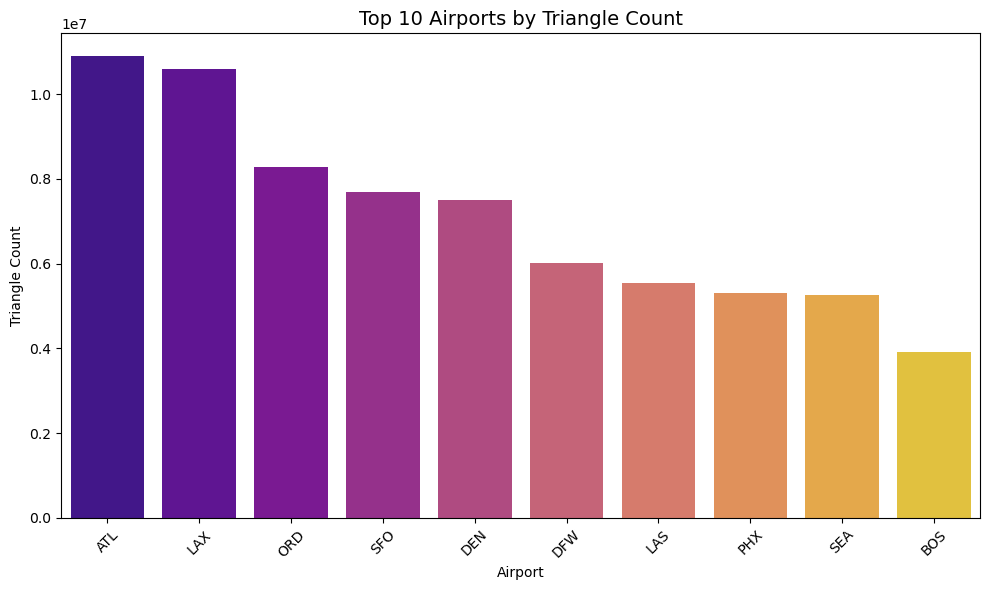

In [25]:
# Get top 10 airports by triangle count
top_ten_triangles_pd = (
    triangle_count_df
    .orderBy(col("triangle_count").desc())
    .limit(10)
    .toPandas()
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_ten_triangles_pd,
    x="id",
    y="triangle_count",
    hue="id",
    palette="plasma",
    legend=False
)

plt.title("Top 10 Airports by Triangle Count", fontsize=14)
plt.xlabel("Airport")
plt.ylabel("Triangle Count")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


### Compute the total number of triangles in the graph

The total number of triangles is obtained by summing the triangle counts of all nodes and dividing the result by three, since each triangle is counted once at each of its three vertices.

In [26]:
total_triangles = (
    triangle_count_df
    .agg(spark_sum("triangle_count").alias("sum_triangles")) # total number of triangle occurrences across all nodes
    .collect()[0]["sum_triangles"] // 3 # aggregation produces only one row
)

print(f"Total number of triangles in the graph: {total_triangles}")

Total number of triangles in the graph: 41892822


This high value reflects the dense connectivity around major hub airports, where many pairs of neighboring airports are also directly connected

### Compute a centrality measure of your choice natively on Spark using Graphframes

Centrality measures how important a node is in a network. In the context of a flight network, central airports correspond to major hubs that maintain a large number of direct connections with other airports.

In this analysis, degree centrality is used as the chosen centrality measure. Degree centrality is computed based on the total number of incoming and outgoing flights associated with each airport and is normalized by the total number of airports in the network. This measure provides a scalable way to identify the most important airports using native Spark operations.

Degree Centrality (V) = Total Degree (V) / N - 1

In [27]:
num_vertices = vertices_df.count() # number of vertices

degree_centrality_df = (
    degree_df
    .withColumn(
        "degree_centrality",
        col("total_degree") / lit(num_vertices - 1) # lit converts the Python value into a Spark column
    )
)

degree_centrality_df.select(
    "id",
    "in_degree",
    "out_degree",
    "total_degree",
    round(col("degree_centrality"), 2).alias("degree_centrality")
).orderBy(col("degree_centrality").desc()).show(10)

+---+---------+----------+------------+-----------------+
| id|in_degree|out_degree|total_degree|degree_centrality|
+---+---------+----------+------------+-----------------+
|ATL|     1902|      1916|        3818|            12.52|
|ORD|     1152|      1176|        2328|             7.63|
|DEN|     1106|      1034|        2140|             7.02|
|LAX|     1042|      1028|        2070|             6.79|
|DFW|      982|       972|        1954|             6.41|
|SFO|      874|       841|        1715|             5.62|
|PHX|      781|       814|        1595|             5.23|
|LAS|      704|       735|        1439|             4.72|
|SEA|      711|       665|        1376|             4.51|
|DTW|      670|       645|        1315|             4.31|
+---+---------+----------+------------+-----------------+
only showing top 10 rows



#### Top 10 Airports by Degree Centrality Visualization

In [28]:
top_ten_central_airports = (
    degree_centrality_df
    .orderBy(col("degree_centrality").desc())
    .limit(10)
    .select("id")
)

top_airports_list = [row["id"] for row in top_ten_central_airports.collect()]

In [29]:
subgraph_edges_pd = (
    edges_df
    .filter(
        col("src").isin(top_airports_list) &
        col("dst").isin(top_airports_list)
    )
    .toPandas()
)

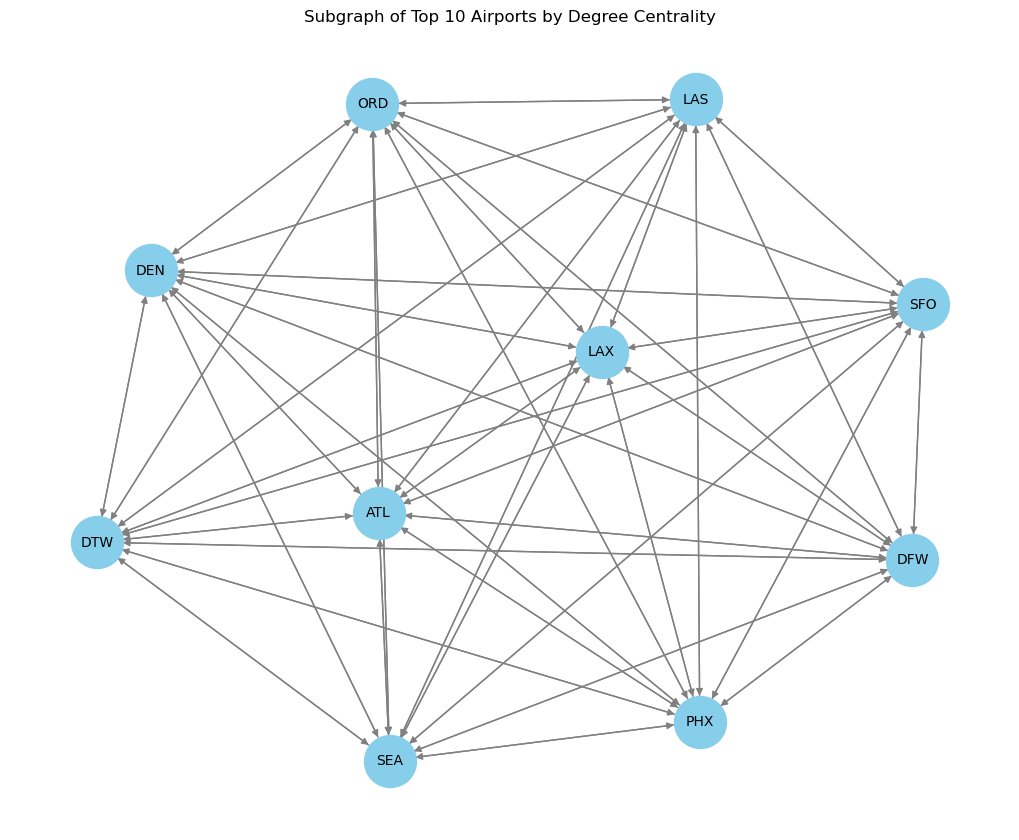

In [30]:
G = nx.from_pandas_edgelist(
    subgraph_edges_pd,
    source="src",
    target="dst",
    create_using=nx.DiGraph()
)

plt.figure(figsize=(10, 8))
pos = nx.spring_layout(G, seed=42)

nx.draw(
    G,
    pos,
    with_labels=True,
    node_size=1400,
    node_color="skyblue",
    edge_color="gray",
    font_size=10,
    arrows=True
)

plt.title("Subgraph of Top 10 Airports by Degree Centrality")
plt.show()


### Implement the PageRank algorithm natively on Spark using Graphframes

PageRank measures the importance of a node based on how many connections it has and also on how important its neighbors are.

In a flight network:  
    - An airport is important if it is connected to other important airports  
    - This captures influence better than the degree alone

In [31]:
damping_factor = 0.85 # this represents the probability of continuing the random walk
num_iterations = 10   # fixed number of iterations is used
num_vertices = vertices_df.count() # total number of airports (nodes) in the graph

In [32]:
# Initializing PageRank
pagerank_df = vertices_df.withColumn(
    "rank",
    lit(1.0 / num_vertices)
) # each airport starts with the same rank value: 1 / N

In [33]:
# Computing out-degrees
out_degree_df = (
    edges_df
    .groupBy("src")
    .count()
    .withColumnRenamed("count", "out_degree")
) # counts the number of outgoing flights from an airport

In [34]:
# Iterative PageRank computation
for i in range(num_iterations):

    # Join PageRank with outgoing edges
    # Associates each outgoing edge with the rank of its source airport
    contributions_df = (
        edges_df
        .join(pagerank_df, edges_df.src == pagerank_df.id)
        .join(out_degree_df, on="src")
        .select(
            col("dst").alias("id"),
            (col("rank") / col("out_degree")).alias("contribution") # Each airport distributes its rank equally across its outgoing flights
        )
    )

    # Aggregate incoming contributions
    aggregated_df = (
        contributions_df
        .groupBy("id") # groups contributions by destination airport
        .agg(spark_sum("contribution").alias("sum_contrib"))
    )

    # Update PageRank values using damping factor
    pagerank_df = (
        vertices_df # ensures all airports are included
        .join(aggregated_df, on="id", how="left")
        .fillna(0.0, subset=["sum_contrib"]) # assigns zero contribution to airports with no incoming rank
        .withColumn(
            "rank",
            (lit(1 - damping_factor) / lit(num_vertices)) +
            lit(damping_factor) * col("sum_contrib")
        )
        .select("id", "rank")
    )

In [35]:
pagerank_df.select(
    "id",
    round(col("rank"), 5).alias("rank")
).orderBy(col("rank").desc()).show(10)

+---+-------+
| id|   rank|
+---+-------+
|ATL|0.06593|
|ORD|0.03896|
|DEN| 0.0358|
|DFW|0.03429|
|LAX|0.02832|
|SFO|0.02684|
|MSP|0.02524|
|DTW|0.02358|
|PHX|0.02324|
|SEA|0.02287|
+---+-------+
only showing top 10 rows



The PageRank results highlight major hub airports such as ATL, ORD, DEN, and DFW as the most important nodes in the flight network. Unlike degree-based metrics, PageRank accounts for the importance of neighboring airports, resulting in slight differences in ranking while consistently identifying key hubs.

#### Top 10 Airports by PageRank Visualization

In [36]:
top_ten_pagerank_pd = (
    pagerank_df
    .select("id", round(col("rank"), 5).alias("rank"))
    .orderBy(col("rank").desc())
    .limit(10)
    .toPandas()
)

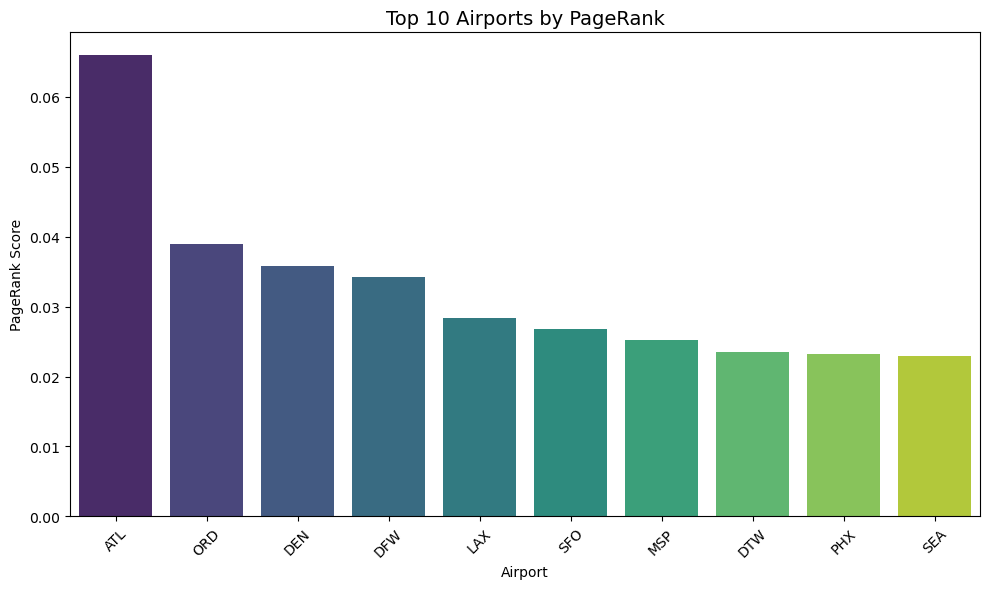

In [37]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_ten_pagerank_pd,
    x="id",
    y="rank",
    hue="id",
    palette="viridis",
    legend=False
)

plt.title("Top 10 Airports by PageRank", fontsize=14)
plt.xlabel("Airport")
plt.ylabel("PageRank Score")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


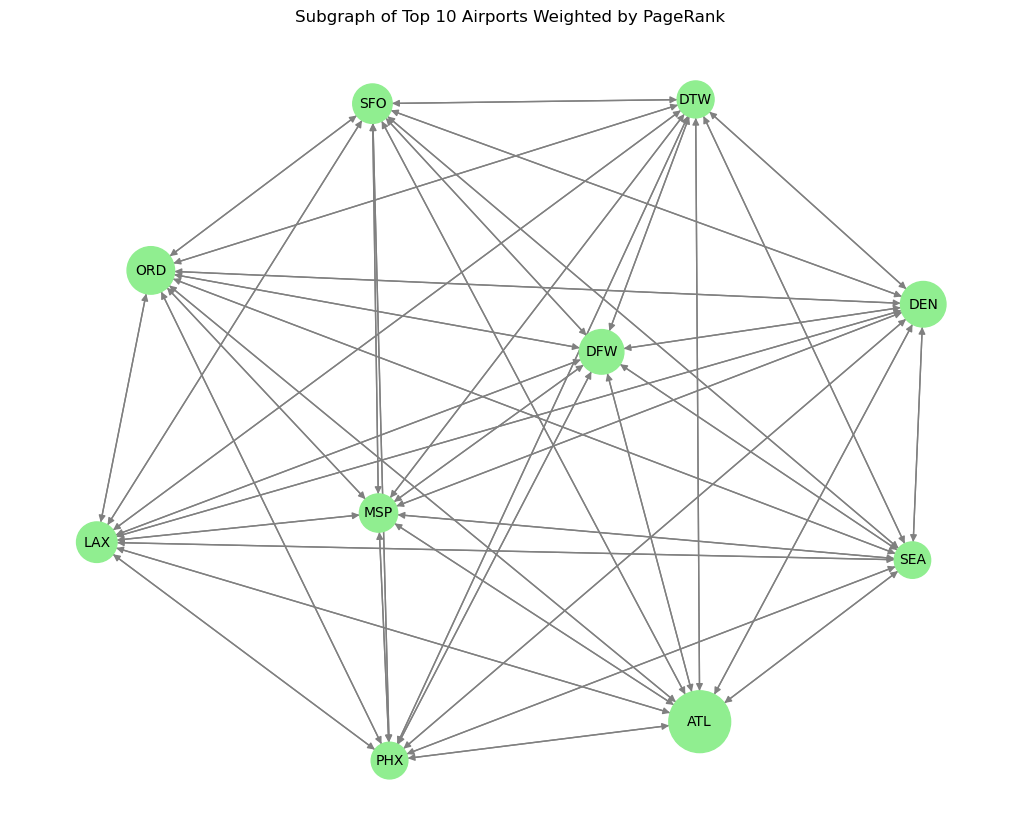

In [38]:
top_airports = top_ten_pagerank_pd["id"].tolist()

subgraph_edges_pd = (
    edges_df
    .filter(
        col("src").isin(top_airports) &
        col("dst").isin(top_airports)
    )
    .toPandas()
)

G = nx.from_pandas_edgelist(
    subgraph_edges_pd,
    source="src",
    target="dst",
    create_using=nx.DiGraph()
)

# Map PageRank to node sizes
pagerank_dict = dict(zip(top_ten_pagerank_pd["id"], top_ten_pagerank_pd["rank"]))
node_sizes = [pagerank_dict.get(node, 0) * 30000 for node in G.nodes()]

plt.figure(figsize=(10, 8))
pos = nx.spring_layout(G, seed=42)

nx.draw(
    G,
    pos,
    with_labels=True,
    node_size=node_sizes,
    node_color="lightgreen",
    edge_color="gray",
    font_size=10,
    arrows=True
)

plt.title("Subgraph of Top 10 Airports Weighted by PageRank")
plt.show()


Larger nodes = higher PageRank

###  Find the group of the most connected airports

This can mean either:  
    - Airports that have the highest number of connections (in and out degree)  
    - A group of airports that are highly connected with each other  

Since degree-based connectivity has already been analyzed earlier, we address the second interpretation in this section by identifying a group of airports that are densely interconnected within the flight network.

In [39]:
# Identifying groups of airports where every airport can reach every other airport
scc_df = flight_graph.stronglyConnectedComponents(maxIter=10) # number of iterations

/usr/local/spark/python/pyspark/sql/dataframe.py:147: UserWarning: DataFrame constructor is internal. Do not directly use it.
  warnings.warn("DataFrame constructor is internal. Do not directly use it.")


In [40]:
# Counting how many airports belong to each strongly connected component
component_sizes_df = (
    scc_df
    .groupBy("component")
    .agg(count("*").alias("size"))
    .orderBy(col("size").desc())
)

component_sizes_df.show(10)

+-----------+----+
|  component|size|
+-----------+----+
|          0| 288|
|17179869233|   2|
|17179869237|   1|
|25769803777|   1|
| 8589934627|   1|
|         26|   1|
| 8589934610|   1|
|         11|   1|
|17179869220|   1|
|17179869186|   1|
+-----------+----+
only showing top 10 rows



There exists one dominant strongly connected component of size 288, representing the group of airports that are highly interconnected with each other.

In [41]:
# Get the ID of the largest strongly connected component
largest_component_id = component_sizes_df.first()["component"]

# Extract airports belonging to the largest SCC
most_connected_airports_df = (
    scc_df
    .filter(col("component") == largest_component_id)
    .select("id")
)

most_connected_airports_df.show(20)

+---+
| id|
+---+
|TUS|
|CVG|
|IAH|
|SIT|
|KOA|
|DEN|
|TXK|
|SBN|
|STL|
|HSV|
|SRQ|
|SJT|
|FAI|
|RDD|
|SAT|
|TPA|
|JAC|
|WYS|
|CID|
|CAE|
+---+
only showing top 20 rows



The largest strongly connected component contains 288 airports. This group represents the core of the flight network, where airports are mutually reachable via directed flight paths. While major hub airports are part of this component, it also includes smaller airports.

#### Visualization of the Most Connected Group of Airports

In [42]:
# Take the largest SCC
largest_scc_df = most_connected_airports_df

# Join with degree to get the most connected airports inside the SCC
scc_top_airports = (
    largest_scc_df
    .join(degree_df, on="id")
    .orderBy(col("total_degree").desc())
    .limit(20)
)

In [43]:
scc_top_list = [row["id"] for row in scc_top_airports.collect()]

scc_edges_pd = (
    edges_df
    .filter(
        col("src").isin(scc_top_list) &
        col("dst").isin(scc_top_list)
    )
    .toPandas()
)

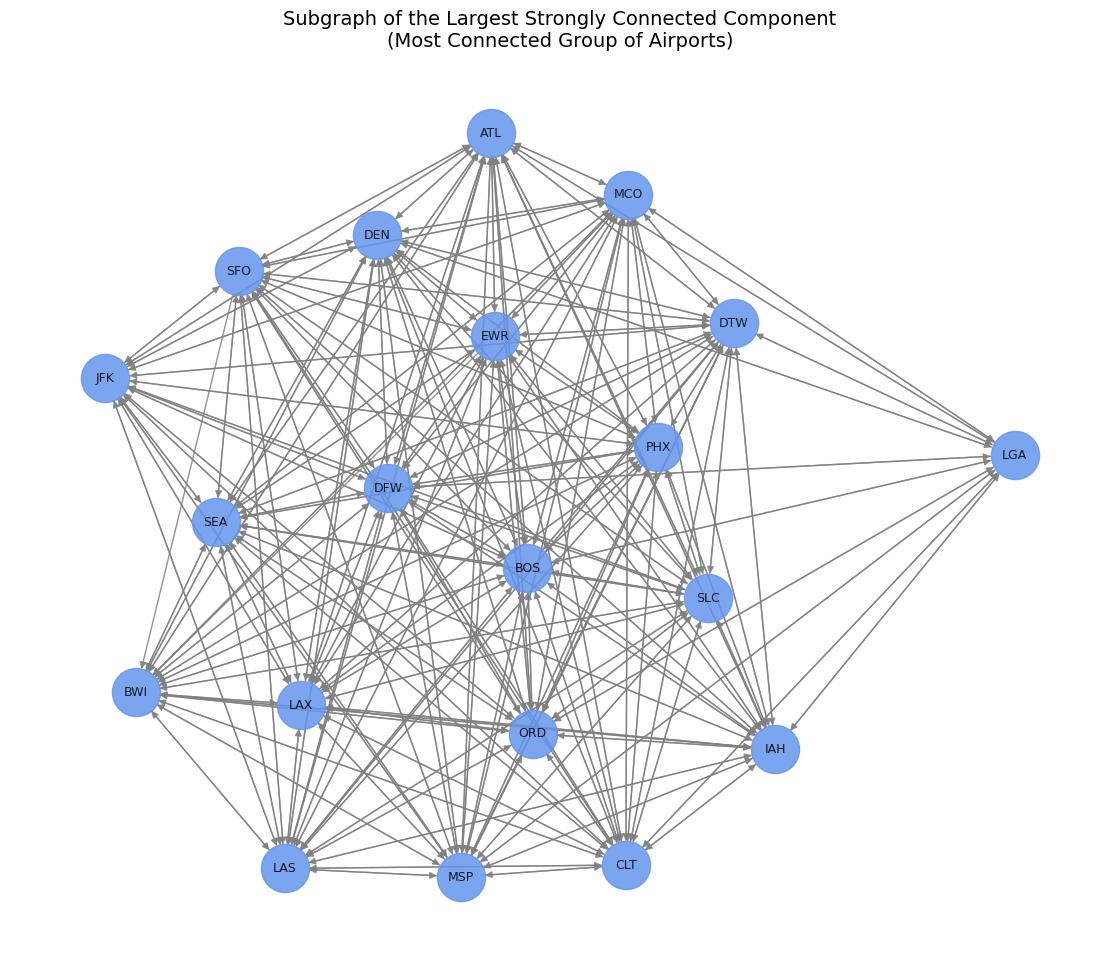

In [44]:
G = nx.from_pandas_edgelist(
    scc_edges_pd,
    source="src",
    target="dst",
    create_using=nx.DiGraph()
)

plt.figure(figsize=(11, 9))

pos = nx.spring_layout(G, seed=42)

nx.draw(
    G,
    pos,
    with_labels=True,
    node_size=1200,
    node_color="cornflowerblue",
    edge_color="gray",
    font_size=9,
    arrows=True,
    alpha=0.85
)

plt.title(
    "Subgraph of the Largest Strongly Connected Component\n"
    "(Most Connected Group of Airports)",
    fontsize=14
)

plt.show()


###  Find the most important airport

In graph analytics, importance is best captured by PageRank, because:  
    - It considers both direct and indirect connections  
    - It accounts for the importance of neighboring airports  
    - It reflects global influence in the network  

According to out interpretation, the most important airport is the one with the highest PageRank score.

In [45]:
pagerank_df.orderBy(col("rank").desc()).show(1)

+---+-------------------+
| id|               rank|
+---+-------------------+
|ATL|0.06593201227928312|
+---+-------------------+
only showing top 1 row



The most important airport in the network is identified using PageRank. ATL achieves the highest PageRank score, indicating that it plays a central role in the flight network by connecting not only to many airports, but also to other highly influential hubs.

###  Compare the results using different metrics (degree, centrality, PageRank)

#### Degree Comparison

In [46]:
# GraphFrames degree (for comparison only)
gf_degree_df = flight_graph.degrees

degree_comparison_df = (
    gf_degree_df
    .withColumnRenamed("id", "airport_id")
    .join(
        degree_df.select(
            col("id").alias("airport_id"),
            col("total_degree")
        ),
        on="airport_id",
        how="inner"
    )
    .withColumnRenamed("degree", "graphframes_degree")
    .orderBy(col("graphframes_degree").desc())
)

degree_comparison_df.show(10)

+----------+------------------+------------+
|airport_id|graphframes_degree|total_degree|
+----------+------------------+------------+
|       ATL|              3818|        3818|
|       ORD|              2328|        2328|
|       DEN|              2140|        2140|
|       LAX|              2070|        2070|
|       DFW|              1954|        1954|
|       SFO|              1715|        1715|
|       PHX|              1595|        1595|
|       LAS|              1439|        1439|
|       SEA|              1376|        1376|
|       DTW|              1315|        1315|
+----------+------------------+------------+
only showing top 10 rows



The degree values computed manually exactly match those produced by the GraphFrames built-in function, confirming the correctness of the manual degree computation.

#### Centrality Comparison

In [47]:
num_vertices = vertices_df.count()

gf_degree_centrality_df = (
    flight_graph.degrees
    .withColumn(
        "gf_degree_centrality",
        col("degree") / lit(num_vertices - 1)
    )
    .select(
        col("id").alias("airport_id"),
        round(col("gf_degree_centrality"), 5).alias("gf_degree_centrality")
    )
)

In [48]:
centrality_comparison_df = (
    gf_degree_centrality_df
    .join(
        degree_centrality_df.select(
            col("id").alias("airport_id"),
            round(col("degree_centrality"), 5).alias("manual_degree_centrality")
        ),
        on="airport_id",
        how="inner"
    )
    .orderBy(col("gf_degree_centrality").desc())
)

centrality_comparison_df.show(10)

+----------+--------------------+------------------------+
|airport_id|gf_degree_centrality|manual_degree_centrality|
+----------+--------------------+------------------------+
|       ATL|            12.51803|                12.51803|
|       ORD|             7.63279|                 7.63279|
|       DEN|             7.01639|                 7.01639|
|       LAX|             6.78689|                 6.78689|
|       DFW|             6.40656|                 6.40656|
|       SFO|             5.62295|                 5.62295|
|       PHX|             5.22951|                 5.22951|
|       LAS|             4.71803|                 4.71803|
|       SEA|             4.51148|                 4.51148|
|       DTW|             4.31148|                 4.31148|
+----------+--------------------+------------------------+
only showing top 10 rows



Degree centrality was computed manually by normalizing the total degree of each airport with respect to the number of vertices in the graph. For validation, the same normalization was applied to the degree values obtained from GraphFrames. The resulting degree centrality values are identical across both approaches, confirming the correctness of the manual implementation.

#### PageRank Comparison

In [57]:
# GraphFrames PageRank (for comparison only)
gf_pagerank_df = (
    flight_graph
    .pageRank(
        resetProbability=1 - damping_factor,
        maxIter=num_iterations
    )
    .vertices
    .select(
        col("id").alias("airport_id"),
        col("pagerank").alias("gf_pagerank")
    )
)

/usr/local/spark/python/pyspark/sql/dataframe.py:147: UserWarning: DataFrame constructor is internal. Do not directly use it.
  warnings.warn("DataFrame constructor is internal. Do not directly use it.")
/usr/local/spark/python/pyspark/sql/dataframe.py:168: UserWarning: DataFrame.sql_ctx is an internal property, and will be removed in future releases. Use DataFrame.sparkSession instead.
  warnings.warn(


In [58]:
pagerank_comparison_df = (
    gf_pagerank_df
    .join(
        pagerank_df.select(
            col("id").alias("airport_id"),
            round(col("rank"), 5).alias("manual_pagerank")
        ),
        on="airport_id",
        how="inner"
    )
    .select(
        "airport_id",
        round(col("gf_pagerank"), 5).alias("gf_pagerank"),
        "manual_pagerank"
    )
    .orderBy(col("gf_pagerank").desc())
)

pagerank_comparison_df.show(10)

+----------+-----------+---------------+
|airport_id|gf_pagerank|manual_pagerank|
+----------+-----------+---------------+
|       ATL|   20.43253|        0.06593|
|       ORD|   12.07279|        0.03896|
|       DEN|   11.09468|         0.0358|
|       DFW|   10.62716|        0.03429|
|       LAX|    8.77641|        0.02832|
|       SFO|    8.31639|        0.02684|
|       MSP|    7.82338|        0.02524|
|       DTW|    7.30613|        0.02358|
|       PHX|    7.20296|        0.02324|
|       SEA|    7.08665|        0.02287|
+----------+-----------+---------------+
only showing top 10 rows



The PageRank values produced by the manual implementation and GraphFrames differ in scale due to different normalization conventions. The manual implementation produces normalized PageRank values that sum to one, while GraphFrames returns unnormalized scores. Despite this difference, both approaches yield identical ranking orders of the most important airports, confirming the correctness of the manual PageRank implementation.

###  (Optional) Draw the heatmap of the flights between the airports

A heatmap shows:  
X-axis: Destination airports  
Y-axis: Origin airports  
Color intensity → Number of flights between each pair  

We are drawing a heatmap using only the top 15 airports by degree

In [51]:
top_airports = (
    degree_df
    .orderBy(col("total_degree").desc())
    .limit(15)
    .select("id")
)

top_airports_list = [row["id"] for row in top_airports.collect()]

In [52]:
heatmap_df = (
    edges_df
    .filter(
        col("src").isin(top_airports_list) &
        col("dst").isin(top_airports_list)
    )
    .groupBy("src", "dst")
    .agg(count("*").alias("flight_count"))
    .toPandas()
)

In [53]:
heatmap_matrix = heatmap_df.pivot(
    index="src",
    columns="dst",
    values="flight_count"
).fillna(0)

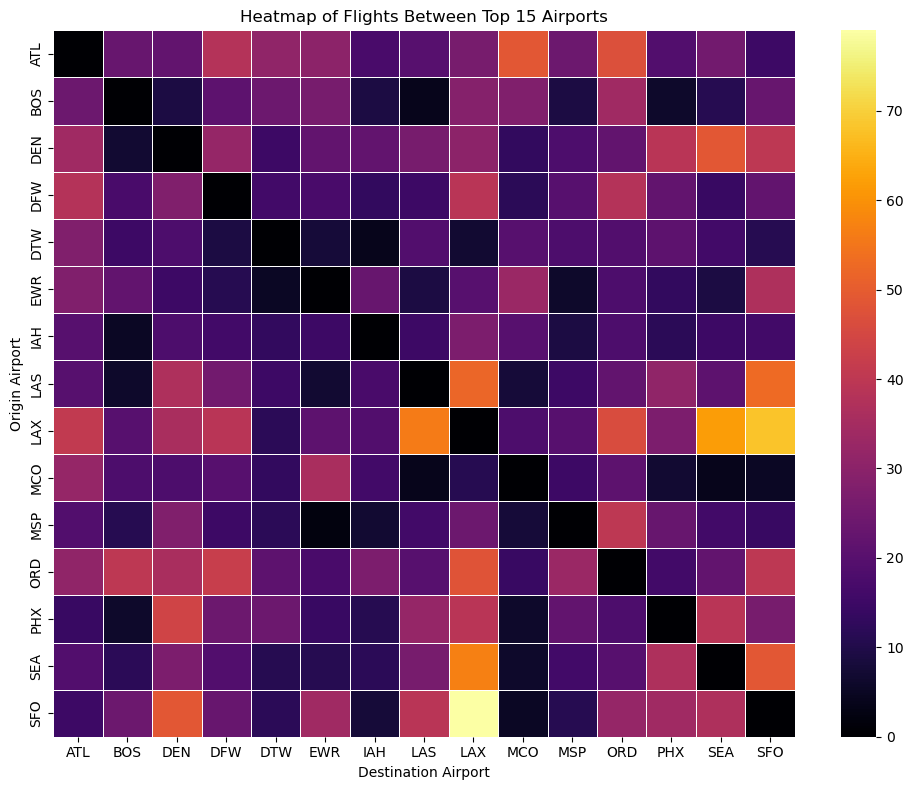

In [56]:
plt.figure(figsize=(10, 8))

sns.heatmap(
    heatmap_matrix,
    cmap="inferno",
    linewidths=0.5
)

plt.title("Heatmap of Flights Between Top 15 Airports")
plt.xlabel("Destination Airport")
plt.ylabel("Origin Airport")

plt.tight_layout()
plt.show()

Darker colors indicate fewer flights, while brighter colors indicate higher traffic volumes between airport pairs.